In [3]:
import re
from pathlib import Path
 
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.table import Table
from astropy.timeseries import LombScargle
 
# Barras de progreso: tqdm.auto elige la versión de notebook (Jupyter) o de terminal.
# Si tqdm no está instalado, el módulo funciona igual, sin barras.
try:
    from tqdm.auto import tqdm
except ImportError:
    class tqdm:                                   # sustituto mínimo sin barra
        def __init__(self, iterable=None, **kw):
            self.iterable = iterable
        def __iter__(self):
            return iter(self.iterable)
        def update(self, n=1):
            pass
        def set_description(self, *a, **k):
            pass
        def set_postfix_str(self, *a, **k):
            pass
        def close(self):
            pass
 
E_S = u.electron / u.second
 
 
# =====================================================================
# Utilidades generales
# =====================================================================
def normalizar_tic(tic):
    """'TIC 123', 'tic123' o 123 -> ('TIC 123', 'tic123')."""
    s = str(tic).strip().upper().replace("TIC", "").strip()
    return f"TIC {s}", f"tic{s}"
 
 
def _carpeta(outdir, tag):
    p = Path(outdir if outdir is not None else tag)
    p.mkdir(parents=True, exist_ok=True)
    return p
 
 
def _escribir_txt(tabla, ruta):
    """Escribe una tabla astropy como texto plano .txt: una fila de encabezado con los
    nombres de columna y valores separados por tabulaciones (abre bien en Excel, pandas
    con sep="\\t", numpy.genfromtxt, TOPCAT, etc.)."""
    tabla.write(str(ruta), format="ascii.basic", delimiter="\t", overwrite=True)
    return str(ruta)
 
 
def elegir_directorio(tic=None, titulo="Selecciona la carpeta donde guardar los datos",
                      inicial=None):
    """Abre un selector de carpetas (tkinter). Si se pasa `tic`, devuelve
    <carpeta elegida>/<tic...>, que es lo que esperan procesar_sistema() y
    analizar_sistema() en `outdir`. Sin entorno gráfico pide la ruta por texto.
    Devuelve None si se cancela."""
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)        # evita que la ventana quede detrás
        ruta = filedialog.askdirectory(title=titulo, initialdir=inicial or str(Path.home()))
        root.destroy()
    except Exception:
        try:
            ruta = input(f"{titulo} (pega la ruta, Enter para cancelar): ").strip().strip('"')
        except (EOFError, KeyboardInterrupt):    # sin entrada interactiva
            ruta = ""
    if not ruta:
        return None
    if tic is not None:
        ruta = str(Path(ruta) / normalizar_tic(tic)[1])    # subcarpeta del sistema
    return ruta
 
 
def exponer_tablas(tablas, namespace):
    """Crea variables tabla_<sector> en el espacio de nombres dado.
    En un notebook/script: exponer_tablas(tablas, globals())."""
    for sec, t in tablas.items():
        namespace[f"tabla_{sec}"] = t
 
 
# =====================================================================
# Corrección de sistemáticos
# =====================================================================
def a_electrones(lc):
    """CBVCorrector exige flujo en e-/s SIN normalizar. Si QLP no declara
    e-/s, solo se re-etiqueta la unidad (los valores no cambian)."""
    out = lc.copy()
    if out.flux.unit != E_S:
        out.flux = out.flux.value * E_S
        out.flux_err = out.flux_err.value * E_S
    return out
 
 
def corregir_regresion(lc, verbose=True):
    """Plan B: regresión sobre fondo y centroides (hasta 3 regresores/PCA)."""
    from lightkurve.correctors import RegressionCorrector, DesignMatrix
 
    cand = [c for c in ("sap_bkg", "centroid_col", "centroid_row", "sap_x", "sap_y")
            if c in lc.colnames]
    if not cand:
        raise ValueError("no hay columnas de fondo/centroide en la curva")
    if verbose:
        print("   regresores disponibles:", cand)
    X = np.column_stack([np.asarray(getattr(lc[c], "value", lc[c]), dtype=float)
                         for c in cand])
    ok = np.all(np.isfinite(X), axis=1)          # descarta filas con NaN en regresores
    lc, X = lc[ok], X[ok]
    sd = X.std(axis=0)
    keep = sd > 0                                # descarta columnas constantes
    if not keep.any():
        raise ValueError("todos los regresores son constantes")
    X = (X[:, keep] - X[:, keep].mean(axis=0)) / sd[keep]
    dm = DesignMatrix(X, name="systematics")
    if X.shape[1] > 3:                           # PCA solo si hay más de 3 columnas
        dm = dm.pca(3)
    dm = dm.append_constant()
    return lc, RegressionCorrector(lc).correct(dm)
 
 
def corregir_sector(lc, outdir=".", sector=None, verbose=True):
    """Corrige un sector: CBV (SingleScale + Spike) y, si falla, regresión.
    Devuelve (raw_normalizado, corregido_normalizado, metodo)."""
    from lightkurve.correctors import CBVCorrector
 
    outdir = Path(outdir)
    sector = sector if sector is not None else lc.meta["SECTOR"]
    if verbose:
        print(f"\n=== Sector {sector} | cámara {lc.meta.get('CAMERA')} "
              f"CCD {lc.meta.get('CCD')} | N={len(lc)} ===")
    lc = lc.remove_nans()                         # sin normalizar todavía
 
    try:
        cbvc = CBVCorrector(a_electrones(lc), interpolate_cbvs=True, extrapolate_cbvs=True)
        cbvc.plot_cbvs(cbv_type=["SingleScale", "Spike"], cbv_indices="ALL")
        plt.savefig(outdir / f"cbvs_s{sector:02d}.png", dpi=150); plt.close("all")
        cbvc.correct(cbv_type=["SingleScale", "Spike"],
                     cbv_indices=[np.arange(1, 9), "ALL"],
                     alpha_bounds=[1e-4, 1e4],
                     target_over_score=0.5, target_under_score=0.8)
        cbvc.diagnose()
        plt.savefig(outdir / f"diagnose_s{sector:02d}.png", dpi=150); plt.close("all")
        if verbose:
            print("   over-fitting :", cbvc.over_fitting_score())
            print("   under-fitting:", cbvc.under_fitting_score())
        cor, metodo = cbvc.corrected_lc, "CBV"
    except Exception as e:
        if verbose:
            print(f"   CBV no disponible/compatible ({type(e).__name__}: {e})")
            print("   -> plan B: RegressionCorrector")
        try:
            lc, cor = corregir_regresion(lc, verbose)
            metodo = "Regresion"
        except Exception as e2:
            if verbose:
                print(f"   plan B también falló ({type(e2).__name__}: {e2}). Sin corrección.")
            cor, metodo = lc, "ninguno"
 
    return lc.normalize(), cor.normalize(), metodo
 
 
# =====================================================================
# Tablas astropy
# =====================================================================
def construir_tabla(raw, cor, tic, sector, metodo):
    """Tabla astropy con la curva corregida de un sector."""
    t = Table()
    t["time_btjd"] = np.asarray(cor.time.value)               # BJD - 2457000
    t["flux_raw_norm"] = (np.asarray(raw.flux.value) if len(raw) == len(cor)
                          else np.full(len(cor), np.nan))
    t["flux_corr"] = np.asarray(cor.flux.value)
    t["flux_corr_err"] = np.asarray(cor.flux_err.value)
    t["quality"] = (np.asarray(cor.quality) if "quality" in cor.colnames
                    else np.zeros(len(cor), dtype=int))
    t["time_btjd"].unit = u.d
    t["time_btjd"].description = "BJD_TDB - 2457000"
    t["flux_corr"].description = "Flujo SAP normalizado y corregido"
    t.meta["TARGET"] = tic
    t.meta["SECTOR"] = int(sector)
    t.meta["METODO"] = metodo
    t.sort("time_btjd")
    return t
 
 
def guardar_tabla(tabla, tic, sector, outdir=None, formatos=("txt",)):
    """Guarda la tabla en los formatos pedidos: 'txt' (por defecto, texto plano con
    tabulaciones), 'ecsv' (texto con unidades y metadatos) y/o 'fits'.
    Se escribe tic<ID>_sXX_qlp_corrected.<ext>. Devuelve la lista de rutas."""
    tic, tag = normalizar_tic(tic)
    outdir = _carpeta(outdir, tag)
    base = outdir / f"{tag}_s{int(sector):02d}_qlp_corrected"
    rutas = []
    if "txt" in formatos:
        rutas.append(_escribir_txt(tabla, f"{base}.txt"))
    if "ecsv" in formatos:
        tabla.write(f"{base}.ecsv", format="ascii.ecsv", overwrite=True)
        rutas.append(f"{base}.ecsv")
    if "fits" in formatos:
        tabla.write(f"{base}.fits", format="fits", overwrite=True)
        rutas.append(f"{base}.fits")
    return rutas
 
 
def cargar_tablas(tic, outdir=None, sectores=None):
    """Lee desde disco las tablas ya generadas (.txt; si no hay, .ecsv) -> {sector: Table}.
    El sector se toma del nombre del archivo. Usa el mismo outdir con el que se guardaron."""
    tic, tag = normalizar_tic(tic)
    outdir = Path(outdir if outdir is not None else tag)
    tablas = {}
    archivos = sorted(outdir.glob(f"{tag}_s*_qlp_corrected.txt"))
    if not archivos:
        archivos = sorted(outdir.glob(f"{tag}_s*_qlp_corrected.ecsv"))
    for f in archivos:
        m = re.search(r"_s(\d+)_qlp_corrected", f.name)
        if m is None:
            continue
        sec = int(m.group(1))
        if sectores is not None and sec not in sectores:
            continue
        if f.suffix == ".txt":
            t = Table.read(str(f), format="ascii.basic", delimiter="\t")
        else:
            t = Table.read(f)
        t.meta["TARGET"] = tic
        t.meta["SECTOR"] = sec
        tablas[sec] = t
    if not tablas:
        print(f"No se encontraron tablas para {tic} en {outdir}/")
    return tablas
 
 
def graficar_curvas(tablas, tic, outdir=None, show=False):
    """Guarda en PNG las curvas de luz de cada sector (SAP normalizado arriba, corregido
    abajo) y un panel con todos los sectores. Devuelve la lista de rutas."""
    tic, tag = normalizar_tic(tic)
    outdir = _carpeta(outdir, tag)
    rutas = []
    items = sorted(tablas.items())
 
    for sec, tab in items:
        t = np.asarray(tab["time_btjd"], dtype=float)
        raw = np.asarray(tab["flux_raw_norm"], dtype=float)
        cor = np.asarray(tab["flux_corr"], dtype=float)
        fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
        ax[0].scatter(t, raw, s=2, c="k", alpha=0.5)
        ax[0].set_ylabel("SAP normalizado")
        ax[0].set_title(f"{tic} - Sector {sec} (método: {tab.meta.get('METODO', '?')})")
        ax[1].scatter(t, cor, s=2, c="tab:red", alpha=0.6)
        ax[1].set_ylabel("flujo corregido")
        ax[1].set_xlabel("BTJD (BJD - 2457000)")
        fig.tight_layout()
        ruta = outdir / f"curva_s{sec:02d}.png"
        fig.savefig(ruta, dpi=150)
        if show:
            plt.show()
        plt.close(fig)
        rutas.append(str(ruta))
 
    if items:
        fig, axes = plt.subplots(len(items), 1, figsize=(12, 2.8 * len(items)), squeeze=False)
        for ax, (sec, tab) in zip(axes[:, 0], items):
            ax.scatter(np.asarray(tab["time_btjd"], dtype=float),
                       np.asarray(tab["flux_corr"], dtype=float), s=2, c="tab:red", alpha=0.6)
            ax.set_ylabel(f"S{sec}")
        axes[0, 0].set_title(f"{tic} - flujo corregido, todos los sectores")
        axes[-1, 0].set_xlabel("BTJD (BJD - 2457000)")
        fig.tight_layout()
        ruta = outdir / "curvas_todos_los_sectores.png"
        fig.savefig(ruta, dpi=150)
        if show:
            plt.show()
        plt.close(fig)
        rutas.append(str(ruta))
    return rutas
 
 
def procesar_sistema(tic, outdir=None, sectores=None, author="QLP",
                     flux_column="sap_flux", quality_bitmask="default", guardar=True,
                     formatos_tabla=("txt",)):
    """Descarga las curvas QLP de un TIC, corrige cada sector y arma una tabla por sector.
    Guarda las tablas en TXT (formatos_tabla=("txt", "fits") o ("txt", "ecsv") para añadir
    otros formatos) y las curvas de luz en PNG (curva_sXX.png). Devuelve {sector: Table}."""
    import lightkurve as lk
 
    tic, tag = normalizar_tic(tic)
    outdir = _carpeta(outdir, tag)
    sr = lk.search_lightcurve(tic, author=author)
    print(sr)
    if len(sr) == 0:
        raise ValueError(f"No hay curvas {author} para {tic}")
    lcs = sr.download_all(flux_column=flux_column, quality_bitmask=quality_bitmask)
    print("Columnas disponibles:", lcs[0].colnames, "| unidad flujo:", lcs[0].flux.unit)
 
    results, tablas = {}, {}
    barra = tqdm(lcs, desc=f"Corrigiendo {tic}")
    for lc in barra:
        sec = int(lc.meta["SECTOR"])
        if sectores is not None and sec not in sectores:
            continue
        barra.set_description(f"Corrigiendo sector {sec}")
        raw, cor, metodo = corregir_sector(lc, outdir, sec)
        results[sec] = (raw, cor, metodo)
        tablas[sec] = construir_tabla(raw, cor, tic, sec, metodo)
        if guardar:
            guardar_tabla(tablas[sec], tic, sec, outdir, formatos=formatos_tabla)
        print(f"   tabla_{sec}: {len(tablas[sec])} filas (método: {metodo})")
 
    # curvas de luz de los datos corregidos, en PNG
    if tablas:
        graficar_curvas(tablas, tic, outdir)
 
    # comparación antes / después
    if results:
        fig, axes = plt.subplots(len(results), 1, figsize=(10, 3 * len(results)), squeeze=False)
        for ax, (sec, (raw, cor, metodo)) in zip(axes[:, 0], results.items()):
            raw.scatter(ax=ax, c="k", s=2, alpha=0.4, label="SAP normalizado")
            cor.scatter(ax=ax, c="tab:red", s=2, alpha=0.6, label=f"corregido ({metodo})")
            ax.set_title(f"{tic} - Sector {sec}")
        plt.tight_layout()
        plt.savefig(outdir / "qlp_before_after.png", dpi=150)
    return tablas
 
 
# =====================================================================
# Periodogramas: Lomb-Scargle (+FAP) y PDM
# =====================================================================
def datos_de_tabla(tabla):
    """Extrae t, y, dy (solo quality==0 y valores finitos)."""
    q = np.asarray(tabla["quality"])
    t = np.asarray(tabla["time_btjd"], dtype=float)
    y = np.asarray(tabla["flux_corr"], dtype=float)
    dy = np.asarray(tabla["flux_corr_err"], dtype=float)
    m = (q == 0) & np.isfinite(t) & np.isfinite(y) & np.isfinite(dy)
    return t[m], y[m], dy[m]
 
 
def pdm_theta(t, y, periodos, nbins=10, progress=False, desc="PDM"):
    """Estadístico theta de Stellingwerf (1978): s^2 / sigma^2 (menor = mejor).
    progress=True muestra una barra tqdm sobre la grilla de periodos."""
    n = len(y)
    var = np.var(y, ddof=1)
    t0 = t.min()
    theta = np.empty(len(periodos))
    for i, P in enumerate(tqdm(periodos, desc=desc, leave=False, disable=not progress)):
        fase = ((t - t0) / P) % 1.0
        idx = np.minimum((fase * nbins).astype(int), nbins - 1)
        cnt = np.bincount(idx, minlength=nbins)
        s1 = np.bincount(idx, weights=y, minlength=nbins)
        s2 = np.bincount(idx, weights=y * y, minlength=nbins)
        ok = cnt > 1
        ss = np.sum(s2[ok] - s1[ok] ** 2 / cnt[ok])
        gl = n - ok.sum()
        theta[i] = (ss / gl) / var if gl > 0 else np.nan
    return theta
 
 
def pdm_fap(t, y, periodos, theta_obs_min, n_perm=100, step=5, nbins=10, rng=None,
            progress=False):
    """FAP del PDM por permutaciones (supone ruido blanco). Resolución mínima 1/(n_perm+1)."""
    rng = rng or np.random.default_rng(42)
    sub = periodos[::step]
    minimos = np.array([np.nanmin(pdm_theta(t, rng.permutation(y), sub, nbins))
                        for _ in tqdm(range(n_perm), desc="PDM FAP (permutaciones)",
                                      leave=False, disable=not progress)])
    return (np.sum(minimos <= theta_obs_min) + 1) / (n_perm + 1)
 
 
def periodograma(t, y, dy, pmin_d=0.05, samples_per_peak=10, fap_levels=(0.1, 0.01, 0.001),
                 n_boot=200, pdm_nbins=10, n_perm=100, perm_step=5, seed=42, progress=True):
    """Lomb-Scargle (FAP Baluev y bootstrap) + PDM (FAP por permutaciones).
    progress=True muestra barras tqdm (etapas, grilla PDM y permutaciones)."""
    T = t.max() - t.min()
    fmin, fmax = 2.0 / T, 1.0 / pmin_d
    kw = dict(minimum_frequency=fmin, maximum_frequency=fmax)
    boot = dict(n_bootstraps=n_boot, random_seed=seed)
    fap_levels = list(fap_levels)
 
    # El bootstrap de astropy no expone progreso, por eso se muestra una barra de etapas.
    etapas = tqdm(total=5, desc="Periodograma", leave=False, disable=not progress)
 
    etapas.set_postfix_str("Lomb-Scargle")
    ls = LombScargle(t, y, dy)
    freq, power = ls.autopower(samples_per_peak=samples_per_peak, **kw)
    i = np.argmax(power)
    res = dict(T=T, freq=freq, periodos=1.0 / freq, power=power, fap_levels=fap_levels,
               P_ls=1.0 / freq[i], p_ls=power[i])
    etapas.update(1)
 
    etapas.set_postfix_str("FAP Baluev")
    res["fap_baluev"] = ls.false_alarm_probability(power[i], method="baluev", **kw)
    res["niv_baluev"] = ls.false_alarm_level(fap_levels, method="baluev", **kw)
    etapas.update(1)
 
    etapas.set_postfix_str(f"FAP bootstrap ({n_boot} remuestreos, sin avance interno)")
    res["fap_boot"] = ls.false_alarm_probability(power[i], method="bootstrap",
                                                 method_kwds=boot, **kw)
    res["niv_boot"] = ls.false_alarm_level(fap_levels, method="bootstrap",
                                           method_kwds=boot, **kw)
    etapas.update(1)
 
    etapas.set_postfix_str("PDM")
    theta = pdm_theta(t, y, res["periodos"], pdm_nbins, progress=progress, desc="PDM")
    j = np.nanargmin(theta)
    res.update(theta=theta, P_pdm=res["periodos"][j], th_min=theta[j])
    etapas.update(1)
 
    etapas.set_postfix_str("FAP PDM")
    res["fap_pdm"] = pdm_fap(t, y, res["periodos"], theta[j], n_perm, perm_step,
                             pdm_nbins, np.random.default_rng(seed), progress=progress)
    etapas.update(1)
    etapas.close()
    return res
 
 
def plegar(ax, t, y, P, titulo, nb=50):
    """Curva plegada (2 ciclos) con mediana por bin de fase en rojo."""
    fase = ((t - t.min()) / P) % 1.0
    ax.scatter(fase, y, s=2, c="k", alpha=0.3)
    ax.scatter(fase + 1, y, s=2, c="k", alpha=0.3)
    edges = np.linspace(0, 1, nb + 1)
    idx = np.clip(np.digitize(fase, edges) - 1, 0, nb - 1)
    med = np.array([np.median(y[idx == b]) if np.any(idx == b) else np.nan
                    for b in range(nb)])
    cen = 0.5 * (edges[:-1] + edges[1:])
    ax.plot(np.r_[cen, cen + 1], np.r_[med, med], "r-", lw=1.5)
    ax.set_title(titulo, fontsize=9)
    ax.set_xlabel("fase")
    ax.set_ylabel("flujo norm.")
 
 
def graficar_periodogramas(res, t, y, tic, sector, outdir=".", show=True):
    """Guarda en PNG (y opcionalmente muestra) la figura de periodogramas y la de plegadas.
    Los PNG se guardan antes de mostrarlos, así que existen aunque show=False."""
    outdir = Path(outdir)
    P_ls, P_pdm = res["P_ls"], res["P_pdm"]
 
    fig = plt.figure(figsize=(14, 7))
    gs = fig.add_gridspec(2, 3)
    ax1 = fig.add_subplot(gs[0, :2])
    ax1.plot(res["periodos"], res["power"], "k", lw=0.7)
    for lev, nb, nbo in zip(res["fap_levels"], res["niv_baluev"], res["niv_boot"]):
        ax1.axhline(nb, ls="--", lw=0.8, c="tab:red", label=f"Baluev FAP={lev}")
        ax1.axhline(nbo, ls=":", lw=0.8, c="tab:blue", label=f"Bootstrap FAP={lev}")
    ax1.axvline(P_ls, c="tab:green", alpha=0.4)
    ax1.set_xscale("log"); ax1.set_xlabel("Periodo [d]"); ax1.set_ylabel("Potencia LS")
    ax1.set_title(f"Lomb-Scargle sector {sector}: P={P_ls:.5f} d, "
                  f"FAP(Baluev)={res['fap_baluev']:.1e}")
    ax1.legend(fontsize=7, ncol=2)
    ax2 = fig.add_subplot(gs[0, 2])
    ax2.plot(res["periodos"], res["theta"], "k", lw=0.7)
    ax2.axvline(P_pdm, c="tab:green", alpha=0.5)
    ax2.set_xscale("log"); ax2.set_xlabel("Periodo [d]"); ax2.set_ylabel(r"$\theta$ (PDM)")
    ax2.set_title(f"PDM: P={P_pdm:.5f} d, FAP(perm)={res['fap_pdm']:.1e}")
    plegar(fig.add_subplot(gs[1, 0]), t, y, P_ls, f"Plegada a P_LS = {P_ls:.5f} d")
    plegar(fig.add_subplot(gs[1, 1]), t, y, 2 * P_ls, f"Plegada a 2 P_LS = {2*P_ls:.5f} d")
    plegar(fig.add_subplot(gs[1, 2]), t, y, P_pdm, f"Plegada a P_PDM = {P_pdm:.5f} d")
    fig.suptitle(f"{tic} - Sector {sector}")
    fig.tight_layout()
    fig.savefig(outdir / f"periodogramas_s{sector:02d}.png", dpi=150)
    if show:
        plt.show()
    plt.close(fig)
 
    cands = [(P_ls, "P_LS"), (2 * P_ls, "2 P_LS"), (P_pdm, "P_PDM"), (2 * P_pdm, "2 P_PDM")]
    figf, axf = plt.subplots(2, 2, figsize=(12, 8))
    for ax, (P, nom) in zip(axf.ravel(), cands):
        plegar(ax, t, y, P, f"Sector {sector} - {nom} = {P:.5f} d")
    figf.suptitle(f"{tic} - Sector {sector}: curvas plegadas (rojo = mediana por bin)")
    figf.tight_layout()
    figf.savefig(outdir / f"folds_s{sector:02d}.png", dpi=150)
    if show:
        plt.show()
    plt.close(figf)
 
 
def analizar_sector(tabla, tic, sector, outdir=".", show=True, **kw):
    """Periodogramas + figuras + ECSV de periodogramas para una tabla. kw -> periodograma()."""
    tic, _ = normalizar_tic(tic)
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    t, y, dy = datos_de_tabla(tabla)
    print(f"\n=== Sector {sector} | N={len(t)} | baseline={t.max()-t.min():.2f} d ===")
    res = periodograma(t, y, dy, **kw)
    print(f"LS : P={res['P_ls']:.6f} d  power={res['p_ls']:.4f}  "
          f"FAP(baluev)={res['fap_baluev']:.3e}  FAP(bootstrap)={res['fap_boot']:.3e}")
    print(f"PDM: P={res['P_pdm']:.6f} d  theta_min={res['th_min']:.4f}  "
          f"FAP(perm)={res['fap_pdm']:.3e}")
    tabper = Table({"freq_cpd": res["freq"], "period_d": res["periodos"],
                    "ls_power": res["power"], "pdm_theta": res["theta"]})
    tabper.meta.update(TARGET=tic, SECTOR=int(sector))
    _escribir_txt(tabper, outdir / f"periodogramas_s{sector:02d}.txt")
    graficar_periodogramas(res, t, y, tic, sector, outdir, show)
    res["N"] = len(t)
    return res
 
 
def analizar_sector(tabla, tic, sector, outdir=".", show=True, **kw):
    """
    Analiza un sector, calcula periodogramas y guarda gráficos.
    Si el vector de tiempo ``t`` queda vacío después de la limpieza,
    la función imprime un aviso y devuelve un diccionario con ``N = 0``
    y el resto de métricas como ``np.nan``.  De esa forma se evita el
    error ``ValueError: zero‑size array to reduction operation maximum``.
    """
    tic, _ = normalizar_tic(tic)
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    # --------------------------------------------------------------
    # 1️⃣ Guard contra datos vacíos (la corrección principal)
    # --------------------------------------------------------------
    t, y, dy = datos_de_tabla(tabla)
    if len(t) == 0:
        print(f"   No data for sector {sector}, skipping periodograms.")
        return {
            "N": 0,
            "P_ls": np.nan,
            "p_ls": np.nan,
            "fap_baluev": np.nan,
            "fap_boot": np.nan,
            "P_pdm": np.nan,
            "th_min": np.nan,
            "fap_pdm": np.nan,
        }
    # --------------------------------------------------------------
    # 2️⃣ Código original (no se modificó)
    # --------------------------------------------------------------
    print(f"\n=== Sector {sector} | N={len(t)} | baseline={t.max()-t.min():.2f} d ===")
    res = periodograma(t, y, dy, **kw)
    print(
        f"LS : P={res['P_ls']:.6f} d  power={res['p_ls']:.4f}  "
        f"FAP(baluev)={res['fap_baluev']:.3e}  FAP(bootstrap)={res['fap_boot']:.3e}"
    )
    print(
        f"PDM: P={res['P_pdm']:.6f} d  theta_min={res['th_min']:.4f}  "
        f"FAP(perm)={res['fap_pdm']:.3e}"
    )
    tabper = Table({
        "freq_cpd": res["freq"],
        "period_d": res["periodos"],
        "ls_power": res["power"],
        "pdm_theta": res["theta"],
    })
    tabper.meta.update(TARGET=tic, SECTOR=int(sector))
    _escribir_txt(tabper, outdir / f"periodogramas_s{sector:02d}.txt")
    graficar_periodogramas(res, t, y, tic, sector, outdir, show)
    res["N"] = len(t)
    return res


Carpeta base elegida: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Lightkurve

 Iniciando pipeline para el sistema: TIC 465945338
SearchResult containing 6 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 10 2019    QLP    1800   465945338      0.0
  1 TESS Sector 11 2019    QLP    1800   465945338      0.0
  2 TESS Sector 37 2021    QLP     600   465945338      0.0
  3 TESS Sector 63 2023    QLP     200   465945338      0.0
  4 TESS Sector 64 2023    QLP     200   465945338      0.0
  5 TESS Sector 90 2025    QLP     200   465945338      0.0
Columnas disponibles: ['time', 'flux', 'flux_err', 'cadenceno', 'sap_flux', 'kspsap_flux', 'kspsap_flux_err', 'quality', 'orbitid', 'sap_x', 'sap_y', 'sap_bkg', 'sap_bkg_err', 'kspsap_flux_sml', 'kspsap_flux_lag'] | unidad flujo: 


Corrigiendo TIC 465945338:   0%|          | 0/6 [00:00<?, ?it/s]


=== Sector 10 | cámara 3 CCD 1 | N=1205 ===
   CBV no disponible/compatible (AttributeError: 'CBVCorrector' object has no attribute 'plot_cbvs')
   -> plan B: RegressionCorrector
   regresores disponibles: ['sap_bkg', 'sap_x', 'sap_y']
   plan B también falló (ValueError: todos los regresores son constantes). Sin corrección.
   tabla_10: 0 filas (método: ninguno)

=== Sector 11 | cámara 3 CCD 2 | N=1241 ===


C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\_core\_methods.py:222: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\_core\_methods.py:180: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\_core\_methods.py:211: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning: Mean of emp

   CBV no disponible/compatible (AttributeError: 'CBVCorrector' object has no attribute 'plot_cbvs')
   -> plan B: RegressionCorrector
   regresores disponibles: ['sap_bkg', 'sap_x', 'sap_y']
   tabla_11: 1241 filas (método: Regresion)

=== Sector 37 | cámara 3 CCD 1 | N=3461 ===
   CBV no disponible/compatible (AttributeError: 'CBVCorrector' object has no attribute 'plot_cbvs')
   -> plan B: RegressionCorrector
   regresores disponibles: ['sap_bkg', 'sap_x', 'sap_y']
   tabla_37: 3458 filas (método: Regresion)

=== Sector 63 | cámara 3 CCD 1 | N=10942 ===
   CBV no disponible/compatible (AttributeError: 'CBVCorrector' object has no attribute 'plot_cbvs')
   -> plan B: RegressionCorrector
   regresores disponibles: ['sap_bkg', 'sap_x', 'sap_y']
   tabla_63: 10942 filas (método: Regresion)

=== Sector 64 | cámara 3 CCD 2 | N=11276 ===
   CBV no disponible/compatible (AttributeError: 'CBVCorrector' object has no attribute 'plot_cbvs')
   -> plan B: RegressionCorrector
   regresores dispo

Traceback (most recent call last):
  File "C:\Users\darkm\AppData\Local\Temp\ipykernel_30488\2063164269.py", line 46, in <module>
    analizar_sistema(tic=tic, tablas=tablas_corregidas, outdir=outdir,
    ^^^^^^^^^^^^^^^^
NameError: name 'analizar_sistema' is not defined. Did you mean: 'analizar_sector'?


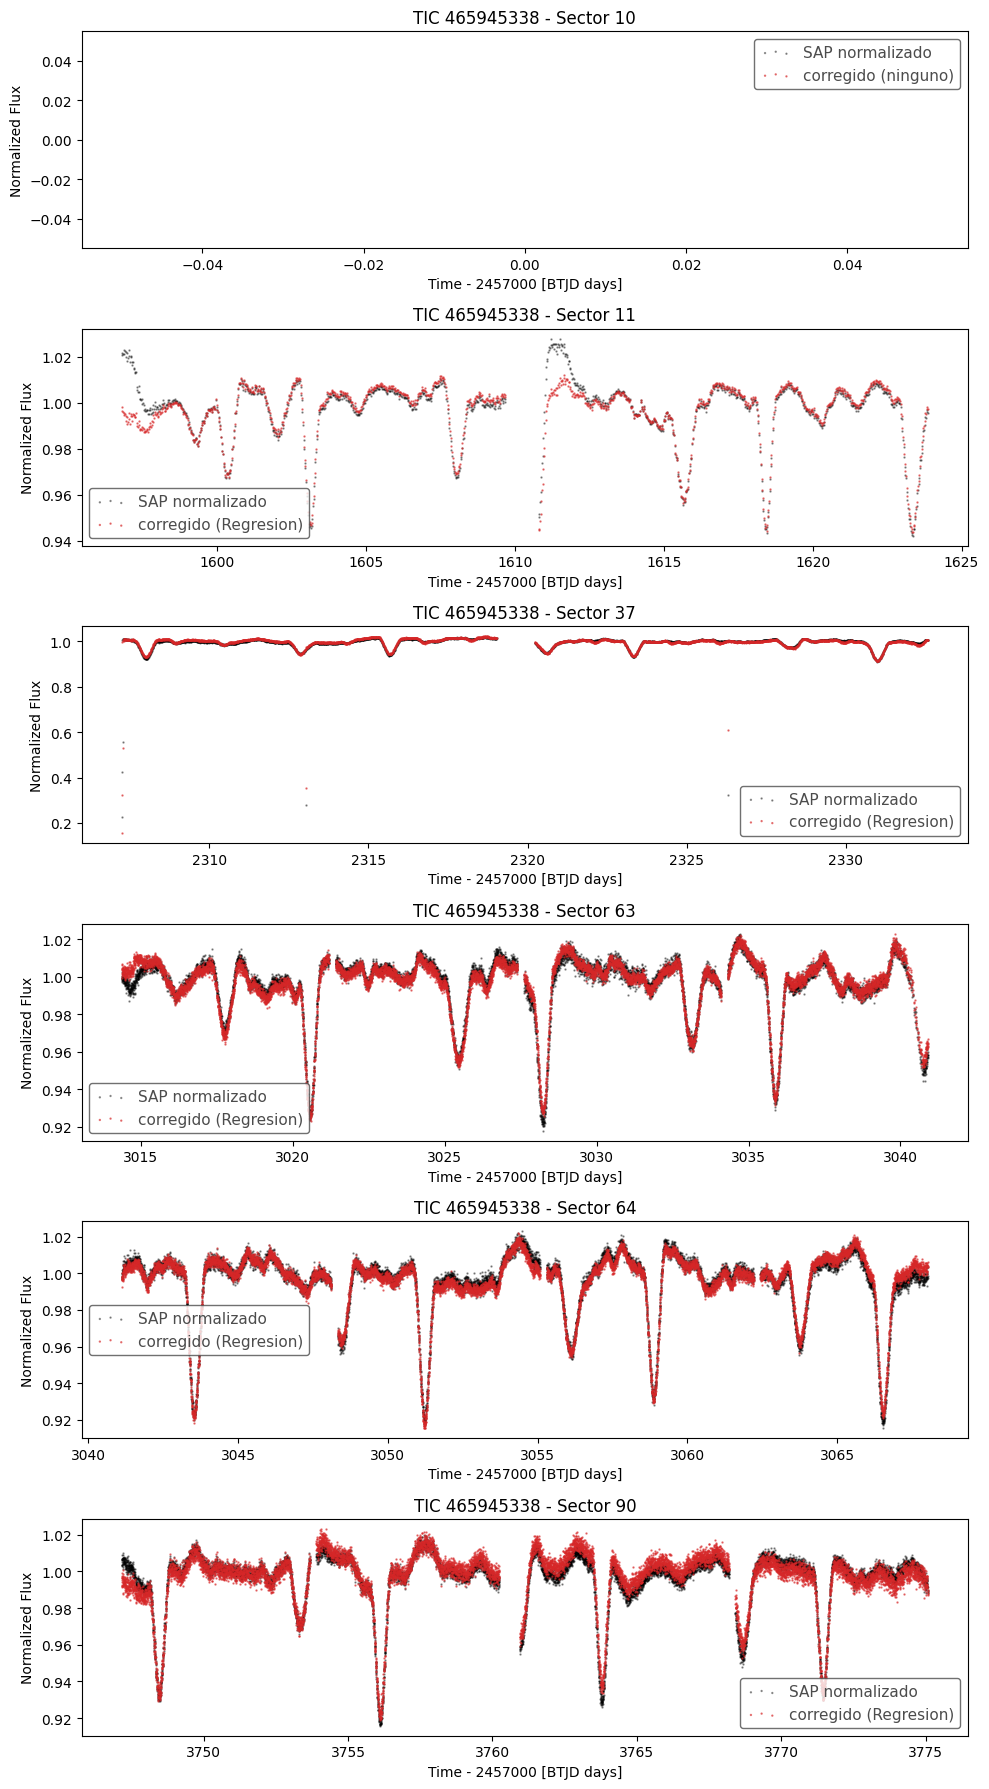

In [4]:
if __name__ == "__main__":
    import argparse
    import traceback
 
    parser = argparse.ArgumentParser(description="Descarga, corrige y analiza curvas de luz QLP de TESS.")
    parser.add_argument("tics", type=str, nargs="*",
                        help="ID(s) del sistema(s) a analizar (ej. '273985861' 'TIC 12345678')")
    parser.add_argument("-s", "--sectores", type=int, nargs="+", default=None,
                        help="Lista de sectores a procesar (ej. -s 1 2 3). Si se omite, procesa todos.")
    parser.add_argument("-o", "--outdir", type=str, default=None,
                        help="Directorio de salida base. Se crea una subcarpeta por TIC.")
    parser.add_argument("--sin-dialogo", action="store_true",
                        help="No abre la ventana para elegir carpeta; usa la carpeta por defecto.")
    parser.add_argument("--con-fits", action="store_true",
                        help="Guarda además cada tabla en FITS (por defecto solo TXT + PNG).")
    parser.add_argument("--hide-plots", action="store_true",
                        help="Guarda los gráficos en disco pero no los muestra.")
 
    # parse_known_args ignora los argumentos que inyecta Jupyter/VS Code (--f=..., etc.)
    args, _desconocidos = parser.parse_known_args()
 
    if not args.tics:
        args.tics = ["TIC 465945338"]
 
    # Selector de carpeta: se abre si no diste -o ni --sin-dialogo
    if not args.outdir and not args.sin_dialogo:
        args.outdir = elegir_directorio(titulo="Selecciona la carpeta base donde guardar los datos")
        if args.outdir:
            print(f"Carpeta base elegida: {args.outdir}")
        else:
            print("No se eligió carpeta: se usará la carpeta por defecto (tic<ID>/ junto al script).")
 
    formatos = ("txt", "fits") if args.con_fits else ("txt",)
 
    for tic in args.tics:
        print(f"\n{'='*50}\n Iniciando pipeline para el sistema: {tic}\n{'='*50}")
        try:
            _, tag = normalizar_tic(tic)
            outdir = str(Path(args.outdir) / tag) if args.outdir else None   # subcarpeta por TIC
 
            tablas_corregidas = procesar_sistema(tic=tic, outdir=outdir,
                                                 sectores=args.sectores, guardar=True,
                                                 formatos_tabla=formatos)
            if tablas_corregidas:
                print(f"\nCalculando periodogramas para {len(tablas_corregidas)} sector(es)...")
                analizar_sistema(tic=tic, tablas=tablas_corregidas, outdir=outdir,
                                 sectores=args.sectores, show=not args.hide_plots)
                print(f"\n¡Proceso completado para {tic}! Datos en: {outdir or tag}")
            else:
                print(f"\nNo se generaron datos. Verifica si {tic} tiene observaciones QLP "
                      f"en los sectores indicados.")
        except Exception:
            print(f"\nError durante la ejecución de {tic}:")
            traceback.print_exc()          # muestra el traceback completo, no solo el mensaje
 
    print("\nEjecución general finalizada. Revisa las carpetas de salida.")